# Digital Detective: Feature Extraction Challenge
### Case file: Locating a teddy-bear figurine in a cluttered scene

**Aim:** Find the same figurine in a cluttered photograph using five distinctive local visual clues.

**Run in Google Colab:** Upload `close-up_image.jpg` and the `wide_image.jpg` beside this notebook, then choose Runtime → Run all. The saved experiment uses `wide_image.jpg`. Keep the original file bytes to preserve the manual reference. No Drive mount or GPU is needed.

**Evidence rules:** Human annotations are separate from automatic predictions. The search uses the target image and five target-only regions, never the manual scene coordinates. A weak or hidden clue is not drawn as a successful automatic match. Similarity is not probability or accuracy. This is a classical computer vision experiment, not a trained neural network.

In [1]:
from pathlib import Path
import hashlib
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, ConnectionPatch, Polygon, Rectangle
from IPython.display import display, Markdown

cv2.setNumThreads(2)
cv2.setRNGSeed(42)
plt.rcParams.update({'figure.dpi': 115, 'axes.titleweight': 'bold'})

def rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image

def show_img(title, image, figsize=(12, 7)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(rgb(image), cmap='gray' if image.ndim == 2 else None)
    ax.set_title(title, pad=12)
    ax.axis('off')
    plt.show()

print('OpenCV:', cv2.__version__)

OpenCV: 4.14.0


## 1. Image preparation
Read the colour images, preserve a consistent working resolution and convert to grayscale for ORB. Resizing corrects the coordinate-system issue in the previous version. It does not solve object movement or occlusion. Scene annotations are tied to exact known file contents, not a filename.

Target input: 3000 × 4000 pixels
Target working size: 1536 × 2048 pixels
Scene input: 4000 × 3000 pixels
Scene working size: 2048 × 1536 pixels
Active scene: wide_image.jpg


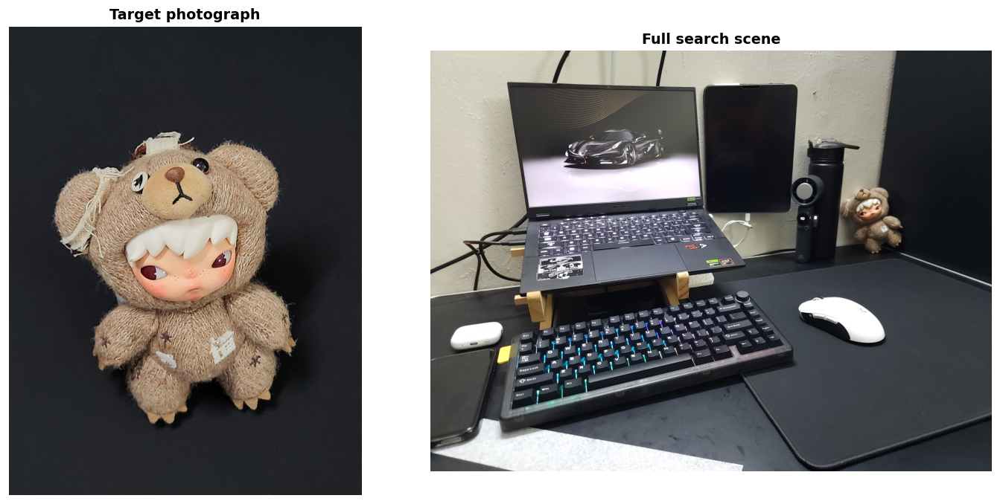

In [2]:
TARGET_PATH = 'close-up_image.jpg'
SCENE_PATH = 'wide_image(1).jpg' if Path('wide_image(1).jpg').is_file() else 'wide_image.jpg'

def load_image(filename):
    path = Path(filename)
    image = cv2.imread(str(path)) if path.is_file() else None
    if image is None:
        raise FileNotFoundError(f'Cannot read {filename}. Upload it beside the notebook or into the current Colab directory.')
    return image

# Standardize the coordinate system used by ALL subsequent cells.
# OpenCV resize expects (width, height), not (height, width).
TARGET_SIZE = (1536, 2048)
SCENE_SIZE = (2048, 1536)

def standardize_image(image, size, label):
    h, w = image.shape[:2]
    print(f'{label} input: {w} × {h} pixels')
    expected_ratio = size[0] / size[1]
    if abs((w / h) / expected_ratio - 1) > 0.02:
        raise ValueError(f'{label}: unexpected aspect ratio. Use the original, uncropped photograph.')
    if (w, h) != size:
        method = cv2.INTER_AREA if w > size[0] and h > size[1] else cv2.INTER_LINEAR
        image = cv2.resize(image, size, interpolation=method)
    print(f'{label} working size: {size[0]} × {size[1]} pixels')
    return image


img_target = standardize_image(load_image(TARGET_PATH), TARGET_SIZE, 'Target')
img_scene = standardize_image(load_image(SCENE_PATH), SCENE_SIZE, 'Scene')
gray_target = cv2.cvtColor(img_target, cv2.COLOR_BGR2GRAY)
gray_scene = cv2.cvtColor(img_scene, cv2.COLOR_BGR2GRAY)
scene_hash = hashlib.sha256(Path(SCENE_PATH).read_bytes()).hexdigest()
print('Active scene:', SCENE_PATH)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, im, title in zip(axes, [img_target, img_scene], ['Target photograph', 'Full search scene']):
    ax.imshow(rgb(im)); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Mission 1 — Identify five distinctive features
The frayed ribbon (texture/edge), bear muzzle (shape), pointed fringe (edge), burgundy eye (contrast/colour) and white chest patch (shape/texture) provide complementary clues. F3 and F4 use the right-hand fringe and eye as seen by the viewer, because the previous left-eye clue is more easily hidden. Their positions are defined in the close-up only. The patches are used as local image descriptors in the improved method.

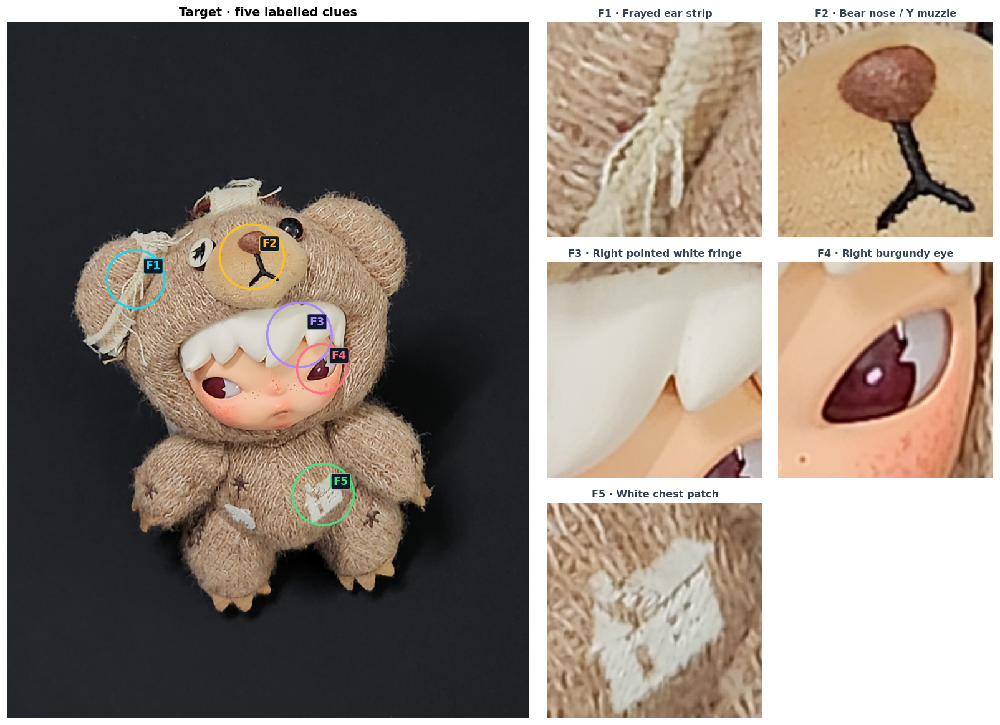

In [3]:
# Only the TARGET contains hardcoded feature positions.
features = [
    dict(id='F1', name='Frayed ear strip', target=(378, 756), radius=85, color='#22d3ee'),
    dict(id='F2', name='Bear nose / Y muzzle', target=(720, 690), radius=95, color='#fbbf24'),
    dict(id='F3', name='Right pointed white fringe', target=(860, 920), radius=95, color='#a78bfa'),
    dict(id='F4', name='Right burgundy eye', target=(925, 1020), radius=72, color='#fb7185'),
    dict(id='F5', name='White chest patch', target=(930, 1390), radius=90, color='#4ade80'),
]
assert (img_target.shape[1], img_target.shape[0]) == TARGET_SIZE
assert (img_scene.shape[1], img_scene.shape[0]) == SCENE_SIZE

def draw_clue(ax, xy, radius, f, offset=(10, 10)):
    ax.add_patch(Circle(xy, radius, fill=False, color=f['color'], linewidth=2.2))
    ax.annotate(f['id'], xy, xytext=offset, textcoords='offset points', color=f['color'],
                fontsize=11, weight='bold', bbox=dict(boxstyle='round,pad=.2', fc='#111827', ec=f['color']))

fig = plt.figure(figsize=(14, 10), layout='constrained')
gs = fig.add_gridspec(3, 3, width_ratios=[2.4, 1, 1])
ax = fig.add_subplot(gs[:, 0]); ax.imshow(rgb(img_target)); ax.axis('off'); ax.set_title('Target · five labelled clues')
for i, f in enumerate(features):
    x, y = f['target']; r = f['radius']
    draw_clue(ax, (x, y), r, f)
    patch = img_target[max(0,y-r):y+r, max(0,x-r):x+r]
    p = fig.add_subplot(gs[i//2, 1+i%2]); p.imshow(rgb(patch)); p.axis('off')
    p.set_title(f"{f['id']} · {f['name']}", fontsize=10, color='#334155')
plt.show()

## 3. Automatic feature extraction. ORB baseline
ORB detects corner-like keypoints and describes local intensity patterns using binary descriptors. Brute-force Hamming matching with cross-check is the reference approach. In the latest scene, the figurine is fully visible but much smaller than in the close-up and viewed at a different angle. Repeated keyboard edges and other desk details can produce ambiguous matches. The baseline is deliberately shown before any verification.

Baseline target keypoints: 500 | scene keypoints: 500
Descriptor shape: (500, 32) (32 bytes = 256 bits per keypoint)


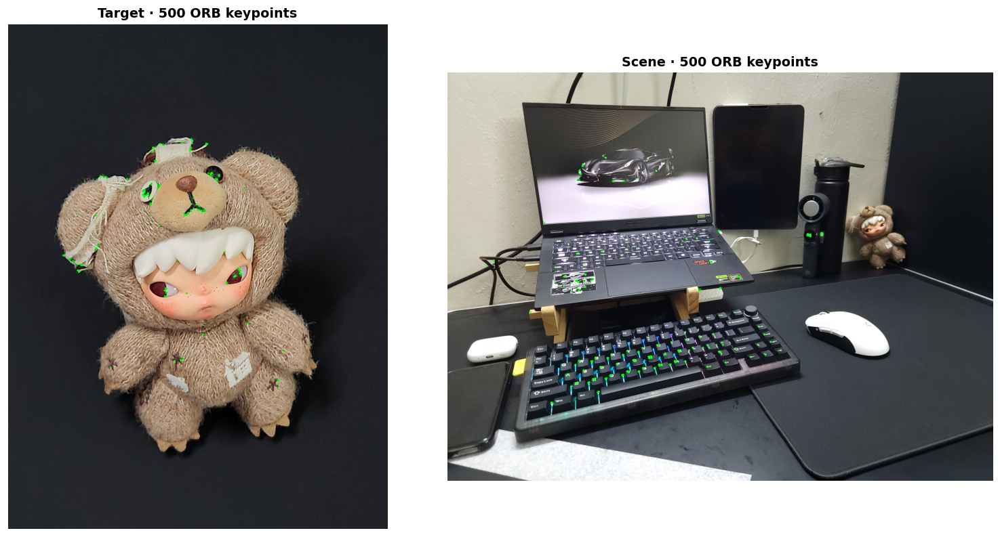

In [4]:
orb_baseline = cv2.ORB_create(nfeatures=500)
kp_target, des_target = orb_baseline.detectAndCompute(gray_target, None)
kp_scene, des_scene = orb_baseline.detectAndCompute(gray_scene, None)
if des_target is None or des_scene is None:
    raise RuntimeError('ORB found no usable descriptors in one of the images.')
print(f'Baseline target keypoints: {len(kp_target)} | scene keypoints: {len(kp_scene)}')
print(f'Descriptor shape: {des_target.shape} (32 bytes = 256 bits per keypoint)')
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, kp, title in zip(axes, [img_target, img_scene], [kp_target, kp_scene], ['Target', 'Scene']):
    marked = cv2.drawKeypoints(image, kp, None, color=(0,255,0))
    ax.imshow(rgb(marked)); ax.set_title(f'{title} · {len(kp)} ORB keypoints'); ax.axis('off')
fig.tight_layout(); plt.show()

Mutual nearest-neighbour matches: 102
Best Hamming distance: 46.0


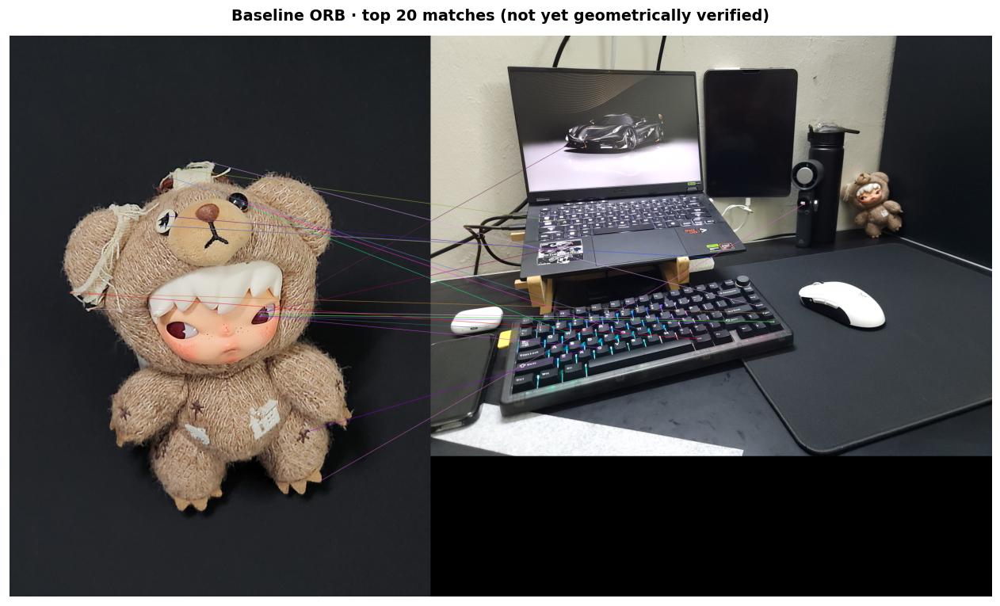

In [5]:
bf_baseline = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
baseline_matches = sorted(bf_baseline.match(des_target, des_scene), key=lambda m: m.distance)
print('Mutual nearest-neighbour matches:', len(baseline_matches))
if baseline_matches:
    print('Best Hamming distance:', baseline_matches[0].distance)
    baseline_view = cv2.drawMatches(img_target, kp_target, img_scene, kp_scene,
                                     baseline_matches[:20], None,
                                     flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    show_img('Baseline ORB · top 20 matches (not yet geometrically verified)', baseline_view, (16,8))

## 4. Mission 2: Automatic search using partial multi-clue matching

Instead of requiring a whole-object match, extract five square colour patches around the marked target clues. For each hypothesized scale and rotation, use normalized cross-correlation (OpenCV `TM_CCOEFF_NORMED`) to compare each patch with possible locations across the scene. Align the resulting similarity maps by the eye anchor so that the five scores refer to a common object pose.

- Search at nine scales (14–30% of target size, in steps of 2 percentage points) and twelve angles (−20° to +35°, in 5° steps), for 108 scale-angle hypotheses. These are explicit size/orientation assumptions, not scene coordinates.
- Average the strongest three of five scores at each location, allowing two clues to be unreliable or hidden. The estimated pose is shared across all clues, unlike independent nearest matches.
- Compare the best candidate to a spatially separate runner-up outside an 80-pixel neighbourhood. Accept only if the top-three average is at least 0.48, at least two clues score at least 0.50, the third-highest score is at least 0.20 and the margin is at least 0.025. These are heuristic thresholds, not calibrated confidence.
- A half-resolution search makes scanning practical and produces approximate positions at full working resolution.

The scene is never cropped to the expected location before the search. The scale and rotation range was developed using the supplied images, so performance outside this range is not established.

In [6]:
SCALES = tuple(np.arange(0.14, 0.301, 0.02))
ANGLES = tuple(range(-20, 36, 5))
SHRINK = .5
ANCHOR = np.array([925., 1020.])
MIN_SCORE = .48
STRONG_SCORE = .50
MIN_MARGIN = .025
MIN_THIRD_SCORE = .20
EXCLUSION_RADIUS = 80  # pixels at full working resolution

def search_scene(scene):
    small = cv2.resize(scene, None, fx=SHRINK, fy=SHRINK, interpolation=cv2.INTER_AREA)
    h, w = small.shape[:2]
    candidates = []
    for scale in SCALES:
        for angle in ANGLES:
            # Rotate and scale the target around its eye anchor, positioned at (200, 200).
            T = cv2.getRotationMatrix2D(tuple(ANCHOR), angle, scale*SHRINK)
            T[:, 2] += np.array([200., 200.]) - ANCHOR
            transformed = cv2.warpAffine(img_target, T, (400, 400), flags=cv2.INTER_AREA)
            maps = []
            for f in features:
                x, y = np.round(T @ np.array([*f['target'], 1])).astype(int)
                r = max(5, round(f['radius']*scale*SHRINK))
                patch = transformed[y-r:y+r+1, x-r:x+r+1]
                score = cv2.matchTemplate(small, patch, cv2.TM_CCOEFF_NORMED)
                dx, dy = x-200-r, y-200-r
                # Translate patch top-left score into a common anchor position.
                aligned = np.full((h, w), -1., dtype=np.float32)
                x0, y0 = max(0,-dx), max(0,-dy)
                x1, y1 = min(w, score.shape[1]-dx), min(h, score.shape[0]-dy)
                aligned[y0:y1,x0:x1] = score[y0+dy:y1+dy,x0+dx:x1+dx]
                maps.append(aligned)
            stack = np.stack(maps)
            combined = np.sort(stack, axis=0)[-3:].mean(axis=0)
            # Save the strongest peak and a spatially separate alternative.
            for _ in range(2):
                _, value, _, xy = cv2.minMaxLoc(combined)
                scores = stack[:,xy[1],xy[0]].copy()
                candidates.append(dict(score=float(value), scale=scale, angle=angle,
                                       anchor=np.array(xy,dtype=float)/SHRINK, scores=scores))
                cv2.circle(combined, xy, round(EXCLUSION_RADIUS*SHRINK), -1., -1)
    candidates.sort(key=lambda r:r['score'], reverse=True)
    best = candidates[0]
    alternatives = [r for r in candidates[1:] if np.linalg.norm(r['anchor']-best['anchor'])>EXCLUSION_RADIUS]
    runner = alternatives[0] if alternatives else None
    best['margin'] = best['score'] - (runner['score'] if runner else -1)
    best['strong'] = int(np.sum(best['scores'] >= STRONG_SCORE))
    best['accepted'] = bool(best['score'] >= MIN_SCORE and best['strong'] >= 2
                            and np.sort(best['scores'])[-3] >= MIN_THIRD_SCORE
                            and best['margin'] >= MIN_MARGIN)
    return best, runner

def project(points, result):
    T = cv2.getRotationMatrix2D(tuple(ANCHOR), result['angle'], result['scale'])
    T[:,2] += result['anchor'] - ANCHOR
    return cv2.transform(np.asarray(points,dtype=np.float32).reshape(-1,1,2),T).reshape(-1,2)

def describe(result):
    print(f"Candidate anchor: {result['anchor'].astype(int)} | scale: {result['scale']:.2f} | angle: {result['angle']}°")
    print(f"Top-three score: {result['score']:.3f} | strong clues: {result['strong']}/5 | peak margin: {result['margin']:.3f}")
    print("Decision:", "ACCEPTED candidate" if result['accepted'] else "UNCERTAIN — no confirmed location")
    for f, value in zip(features,result['scores']):
        print(f"  {f['id']} {f['name']:<28} {value:6.3f}  {'strong' if value >= STRONG_SCORE else 'weak / possibly hidden'}")

best, runner = search_scene(img_scene)
describe(best)
if runner is not None:
    print(f"Separate runner-up: {runner['anchor'].astype(int)}, score {runner['score']:.3f}")

Candidate anchor: [1632  572] | scale: 0.22 | angle: 15°
Top-three score: 0.586 | strong clues: 3/5 | peak margin: 0.118
Decision: ACCEPTED candidate
  F1 Frayed ear strip             -0.012  weak / possibly hidden
  F2 Bear nose / Y muzzle          0.297  weak / possibly hidden
  F3 Right pointed white fringe    0.543  strong
  F4 Right burgundy eye            0.570  strong
  F5 White chest patch             0.645  strong
Separate runner-up: [ 258 1044], score 0.468


### 4.1 Visual evidence of automatic matching
A solid circle and connecting line are shown only for strong local correlations on an accepted pose. Weak clues receive no scene connection. The dashed outline is the projected rectangular extent of the target, not a segmentation of the figurine, and may include surrounding background. A strong score alone is not proof of a correct physical match. The manual reference below supports visual and quantitative evaluation.

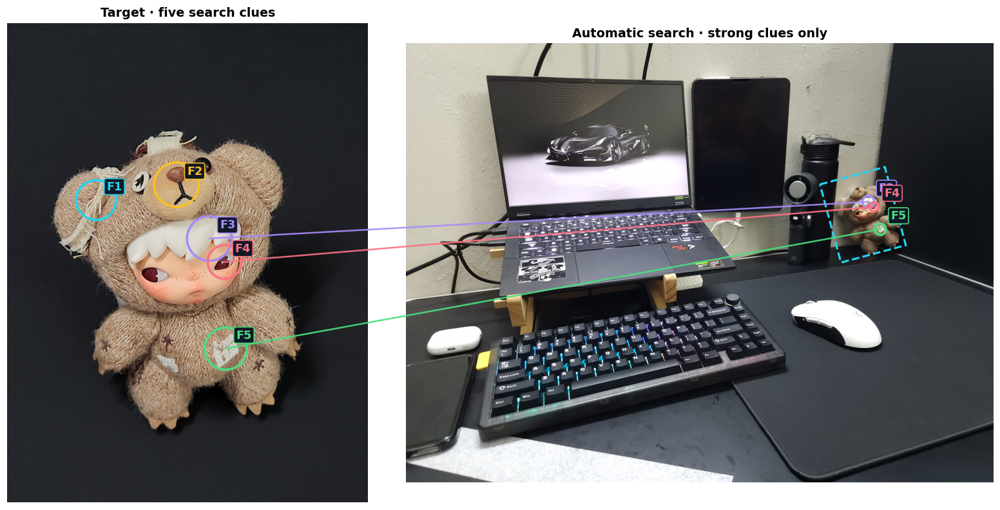

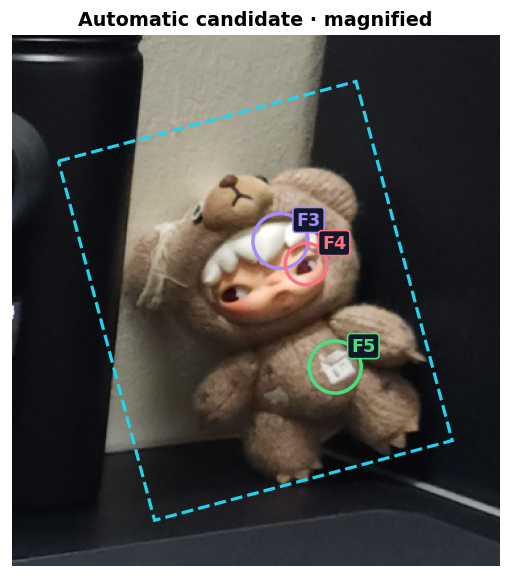

In [7]:
target_outline = np.float32([[190,455],[1255,455],[1255,1740],[190,1740]])

def plot_automatic(scene, result):
    fig, (a,b) = plt.subplots(1,2,figsize=(14,7),gridspec_kw={'width_ratios':[1,1.4]})
    a.imshow(rgb(img_target)); b.imshow(rgb(scene))
    a.set_title('Target · five search clues'); b.set_title('Automatic search · strong clues only')
    for f, score in zip(features, result['scores']):
        draw_clue(a,f['target'],f['radius'],f)
        if result['accepted'] and score >= STRONG_SCORE:
            xy = project([f['target']],result)[0]
            draw_clue(b,xy,max(5,f['radius']*result['scale']),f)
            fig.add_artist(ConnectionPatch(f['target'],xy,'data','data',axesA=a,axesB=b,
                                           color=f['color'],lw=1.6,alpha=.9))
    if result['accepted']:
        b.add_patch(Polygon(project(target_outline,result),closed=True,fill=False,
                            edgecolor='#22d3ee',linewidth=2,linestyle='--'))
    else:
        b.text(.5,.04,'UNCERTAIN — no confirmed location',transform=b.transAxes,ha='center',
               color='white',bbox=dict(fc='#111827'))
    for ax in (a,b): ax.axis('off')
    plt.tight_layout(); plt.show()

def zoom_candidate(scene, result):
    if not result['accepted']:
        return
    points = project(target_outline,result)
    x1,y1=np.floor(points.min(0)-35).astype(int)
    x2,y2=np.ceil(points.max(0)+35).astype(int)
    h,w=scene.shape[:2]; x1=max(0,x1); y1=max(0,y1); x2=min(w,x2); y2=min(h,y2)
    fig,ax=plt.subplots(figsize=(6,6))
    ax.imshow(rgb(scene)); ax.set_xlim(x1,x2); ax.set_ylim(y2,y1)
    ax.add_patch(Polygon(points,closed=True,fill=False,edgecolor='#22d3ee',linestyle='--',lw=2))
    for f, score in zip(features,result['scores']):
        if score>=STRONG_SCORE:
            draw_clue(ax,project([f['target']],result)[0],max(5,f['radius']*result['scale']),f)
    ax.set_title('Automatic candidate · magnified'); ax.axis('off'); plt.show()

plot_automatic(img_scene,best)
zoom_candidate(img_scene,best)

## 5. Mission 2: Manual reference and reliability
The brief asks for human-drawn correspondences and discussion of ambiguous clues. The reference below is used **after** automatic search, strictly for evaluation. All five selected features are visible in the latest scene and can be connected manually. The older partially occluded scene remains in the reference dictionary for optional comparison.

Manual references are enabled only for byte-identical photographs (SHA-256). For a different image, automatic search still runs, but manual evaluation is skipped until new annotations are provided. This prevents the stale-coordinate bug. The reference points are approximate human annotations, so measured errors are relative to those points.

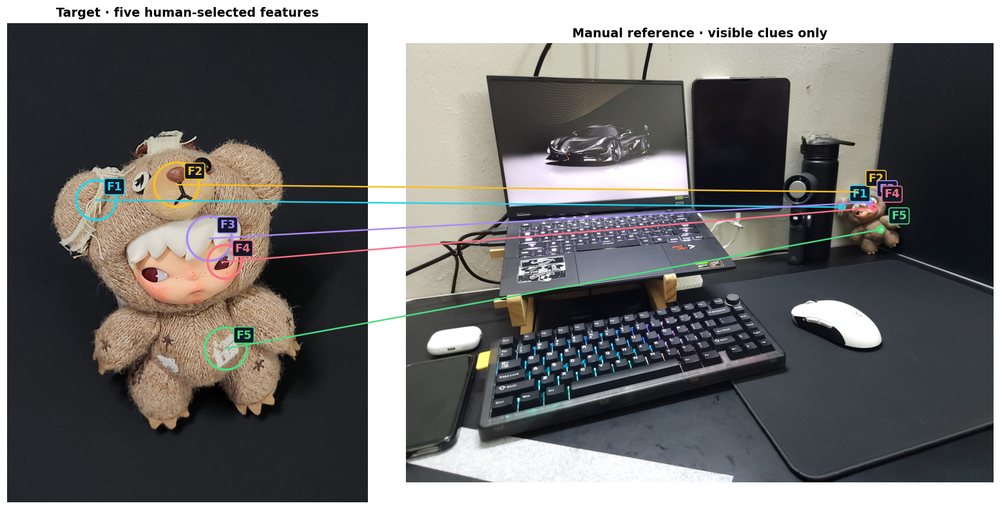

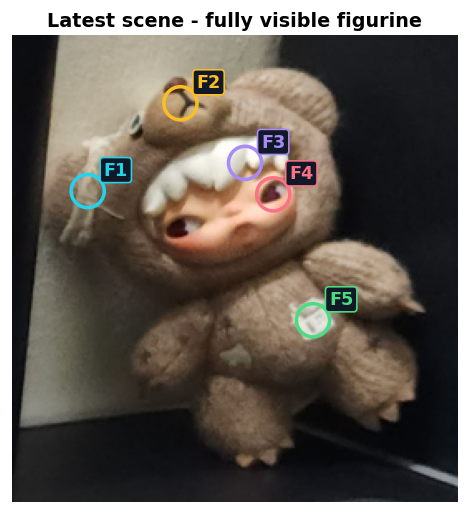

Hidden clues: None


In [8]:
REFERENCES = {
    '1caa4bf11dbe5069bc572fd8e4d5987165211e0be0c34560789ebcc52fd5e56b': {
        'label':'Updated scene · partial occlusion',
        'points': {'F1':None,'F2':None,'F3':(1667,550),'F4':(1677,579),'F5':(1701,653)},
        'box':(1625,490,1778,747)
    },
    '1ce09edc5c07e4a33d101fd9067079b9c725ef08ff0f235281eaa3033dd41d6c': {
        'label':'Original scene · fully visible',
        'points': {'F1':(1388,498),'F2':(1462,467),'F3':(1474,518),'F4':(1482,542),'F5':(1467,623)},
        'box':(1355,450,1550,705)
    }
}

REFERENCES["5add6578e8448ff2e6d7b44fbb1490855365be13143f3f7995eba3e74a4a68e2"] = {
    'label': 'Latest scene - fully visible figurine',
    'points': {
        'F1': (1520, 573),
        'F2': (1576, 520),
        'F3': (1615, 556),
        'F4': (1632, 575),
        'F5': (1656, 651)
    },
    'box': (1494, 499, 1723, 741)
}

reference = REFERENCES.get(scene_hash)

def plot_manual(scene, ref):
    if ref is None:
        print('No manual reference for this exact file; skip manual annotation.')
        return
    fig,(a,b)=plt.subplots(1,2,figsize=(14,7),gridspec_kw={'width_ratios':[1,1.4]})
    a.imshow(rgb(img_target)); b.imshow(rgb(scene))
    a.set_title('Target · five human-selected features'); b.set_title('Manual reference · visible clues only')
    for f in features:
        draw_clue(a,f['target'],f['radius'],f)
        xy=ref['points'][f['id']]
        if xy is not None:
            draw_clue(b,xy,10,f)
            fig.add_artist(ConnectionPatch(f['target'],xy,'data','data',axesA=a,axesB=b,
                                           color=f['color'],lw=1.5))
    for ax in (a,b): ax.axis('off')
    plt.tight_layout(); plt.show()
    x1,y1,x2,y2=ref['box']
    fig,ax=plt.subplots(figsize=(5,6)); ax.imshow(rgb(scene))
    ax.set_xlim(x1-20,x2+20); ax.set_ylim(y2+20,y1-20)
    for f in features:
        xy=ref['points'][f['id']]
        if xy is not None: draw_clue(ax,xy,10,f)
    ax.set_title(ref['label']); ax.axis('off'); plt.show()
    print('Hidden clues:', ', '.join(k for k,v in ref['points'].items() if v is None) or 'None')

plot_manual(img_scene, reference)

### 5.1 Quantitative comparison
Measure location error against the manually marked eye. For strong visible clues, measure distance between projected and manual coordinates (in standardized scene pixels). A match inside the reference rectangle is only a spatial proxy, not proof of identity. No accuracy percentage is claimed from one scene.

In [9]:
def evaluate(result, ref):
    if ref is None:
        print('Manual reference unavailable: no error measurement.'); return
    if result['accepted']:
        error=np.linalg.norm(result['anchor']-np.array(ref['points']['F4']))
        print(f'Anchor localization error: {error:.1f} px')
    else:
        print('Search abstained; no accepted localization.')
    print(f"{'Clue':<6} {'Visibility':<12} {'Similarity':>10} {'Decision':<17} {'Error (px)':>10}")
    for f, score in zip(features,result['scores']):
        xy=ref['points'][f['id']]
        strong=result['accepted'] and score>=STRONG_SCORE
        error=np.linalg.norm(project([f['target']],result)[0]-xy) if strong and xy is not None else None
        print(f"{f['id']:<6} {('hidden' if xy is None else 'visible'):<12} {score:10.3f} "
              f"{('strong' if strong else 'not verified'):<17} {('-' if error is None else f'{error:.1f}'):>10}")
    x1,y1,x2,y2=ref['box']
    top=baseline_matches[:20]
    inside=sum(x1<=kp_scene[m.trainIdx].pt[0]<=x2 and y1<=kp_scene[m.trainIdx].pt[1]<=y2 for m in top)
    print(f'Baseline ORB top matches inside manual region: {inside}/{len(top)} (spatial proxy)')
evaluate(best,reference)

Anchor localization error: 3.0 px
Clue   Visibility   Similarity Decision          Error (px)
F1     visible          -0.012 not verified               -
F2     visible           0.297 not verified               -
F3     visible           0.543 strong                   2.9
F4     visible           0.570 strong                   3.0
F5     visible           0.645 strong                   2.0
Baseline ORB top matches inside manual region: 0/20 (spatial proxy)


## 6. Robustness challenge
Repeat the **full search** for each changed scene, not just the successful pose or a cropped region. Rotation ground truth is transformed using the known synthetic transform; brightness changes preserve coordinates. The negative control replaces the manually marked figurine region with a dark rectangle, keeping the remaining scene unchanged. It is an artificial stress test, not an independent real-world test. An earlier photograph can optionally be evaluated when the file and its matching reference are available.

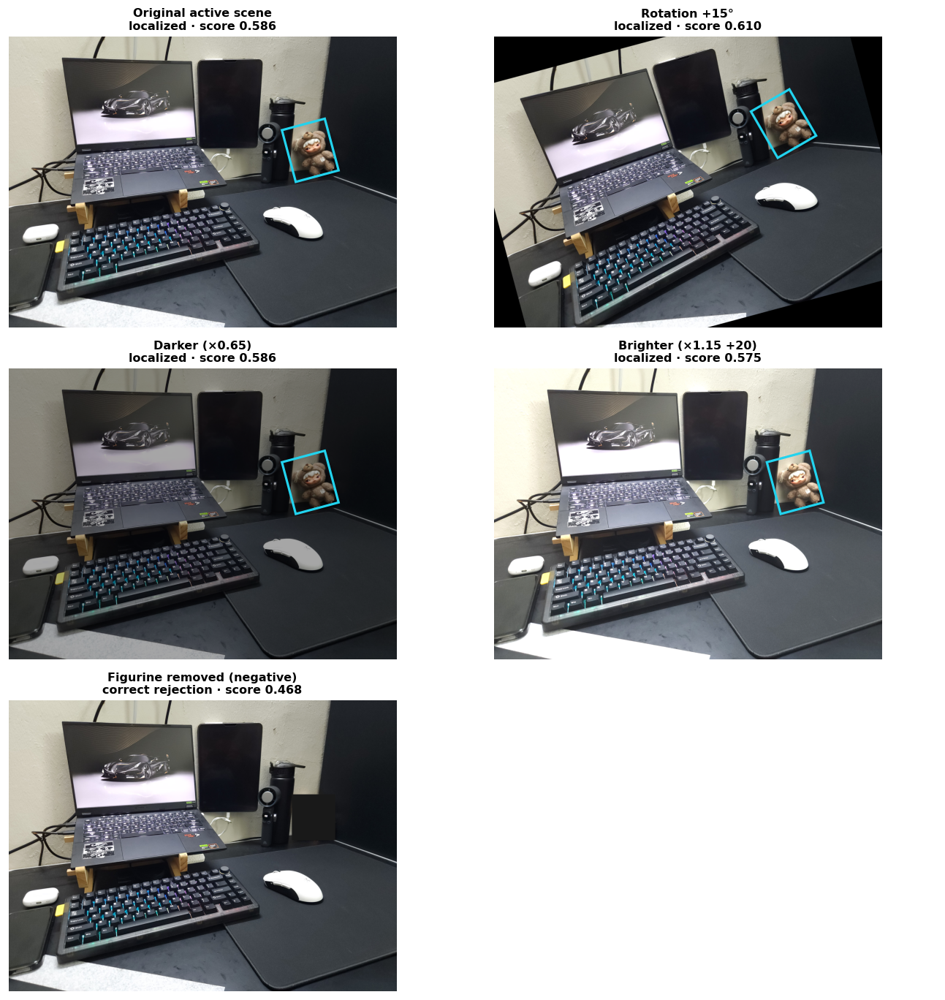

Test                             Score  Margin  Strong  Error px  Outcome
Original active scene            0.586   0.118       3       3.0  localized
Rotation +15°                    0.610   0.135       3       2.6  localized
Darker (×0.65)                   0.586   0.118       3       3.0  localized
Brighter (×1.15 +20)             0.575   0.088       3       3.6  localized
Figurine removed (negative)      0.468   0.002       1         -  correct rejection


In [10]:
h,w=img_scene.shape[:2]
rotation=cv2.getRotationMatrix2D((w/2,h/2),15,1)
identity=np.float32([[1,0,0],[0,1,0]])
tests=[
    ('Original active scene',img_scene,identity,reference,best),
    ('Rotation +15°',cv2.warpAffine(img_scene,rotation,(w,h)),rotation,reference,None),
    ('Darker (×0.65)',cv2.convertScaleAbs(img_scene,alpha=.65,beta=0),identity,reference,None),
    ('Brighter (×1.15 +20)',cv2.convertScaleAbs(img_scene,alpha=1.15,beta=20),identity,reference,None)
]
old_path=Path('wide_image.jpg')
if old_path.is_file():
    old_hash=hashlib.sha256(old_path.read_bytes()).hexdigest()
    if old_hash!=scene_hash and old_hash in REFERENCES:
        old=standardize_image(load_image(str(old_path)),SCENE_SIZE,'Optional original scene')
        tests.append(('Earlier wide photo',old,identity,REFERENCES[old_hash],None))
if reference is not None:
    negative=img_scene.copy()
    x1,y1,x2,y2=reference['box']
    # Evaluation-only intervention; the detector itself receives no location hint.
    negative[y1:y2,x1:x2]=[25,25,25]
    tests.append(('Figurine removed (negative)',negative,identity,None,None))

test_results=[]
fig,axes=plt.subplots((len(tests)+1)//2,2,figsize=(12,4*((len(tests)+1)//2)))
for ax,(name,im,T,ref,cached) in zip(axes.flat,tests):
    r=cached if cached is not None else search_scene(im)[0]
    truth=None if ref is None else T@np.array([*ref['points']['F4'],1])
    err=None if truth is None or not r['accepted'] else float(np.linalg.norm(r['anchor']-truth))
    is_negative='negative' in name
    outcome=('correct rejection' if not r['accepted'] else 'false positive') if is_negative else (
        'uncertain' if not r['accepted'] else 'not evaluated' if err is None else 'localized' if err<=30 else 'wrong location')
    test_results.append((name,r,err,outcome))
    ax.imshow(rgb(im)); ax.axis('off')
    if r['accepted']:
        ax.add_patch(Polygon(project(target_outline,r),closed=True,fill=False,edgecolor='#22d3ee',lw=2))
    ax.set_title(f"{name}\n{outcome} · score {r['score']:.3f}",fontsize=10)
for ax in list(axes.flat)[len(tests):]: ax.axis('off')
plt.tight_layout(); plt.show()

print(f"{'Test':<30} {'Score':>7} {'Margin':>7} {'Strong':>7} {'Error px':>9}  Outcome")
for name,r,err,outcome in test_results:
    print(f"{name:<30} {r['score']:7.3f} {r['margin']:7.3f} {r['strong']:7d} "
          f"{('-' if err is None else f'{err:.1f}'):>9}  {outcome}")

## 7. Reflection & discussion

### 7.1 Feature effectiveness — Which feature was most useful, and why?

The white chest patch (F5) was the most effective feature, achieving the highest normalized correlation score of 0.644. Its distinctive white shape and strong contrast against the brown fabric made it recognizable even when the figurine appeared smaller in the cluttered scene. The burgundy eye (F4, 0.571) and pointed white hair fringe (F3, 0.543) also provided reliable clues. All three exceeded the strong-match threshold of 0.50. Their projected locations were within 2.0–3.0 pixels of the approximate manual reference points in the standardized scene. Combining the clues helped distinguish the figurine from surrounding objects and locate the eye anchor with an error of 3.0 pixels.

### 7.2 Ambiguous features — Which features were less reliable, and why?

The frayed ear strip (F1, −0.012) and bear nose/Y-shaped muzzle (F2, 0.297) were the least reliable automatic clues. Although both were visible and could be matched manually, their correlation scores were below 0.50. Fine ribbon texture can lose detail when the object is reduced in size, while a change in viewing angle can alter the apparent shape of the muzzle. Repetitive edges and textures in the background may also cause ambiguous matches. The baseline ORB method produced 102 mutual nearest-neighbour matches, but none of its 20 best matches fell within the manually marked figurine region. This is a spatial proxy rather than a direct measure of match identity. The improved method avoided forcing weak matches by accepting the location based on consistent evidence from the stronger clues. These results show that useful features should be both distinctive and repeatable.

### 7.3 Robustness challenge — Would the features still work under rotation or different lighting?

The improved method remained effective under the tested changes. Rotating the scene by +15° produced a combined similarity score of 0.610 and a localization error of 2.6 pixels. Reducing brightness produced a score of 0.586 and an error of 3.0 pixels, while increasing brightness produced a score of 0.574 and an error of 3.6 pixels. Three clues remained above the strong-match threshold in each test. Normalized correlation helps reduce sensitivity to uniform brightness changes, while searching multiple scales and angles helps accommodate size and orientation differences. In the negative-control test, the figurine was digitally removed from its annotated region; the method correctly rejected the scene, with a score of 0.468, a peak margin of 0.001 and only one strong clue. However, severe perspective changes, blur, occlusion or different scales may still reduce matching reliability. These synthetic tests on one scene do not establish performance on unseen photographs.

### 7.4 Conclusion

The experiment successfully located the figurine in a cluttered scene. All five features were manually identified and connected, while three were automatically matched with strong scores using the improved scale- and rotation-aware method. The original scene achieved a combined similarity of 0.586, a peak margin of 0.118 and an eye localization error of 3.0 pixels relative to the approximate manual annotation. Compared with the baseline ORB results, the improved method provided more useful localization evidence on this image pair. The experiment demonstrates that distinctive, repeatable features and spatial consistency are important for reliable object localization. Future improvements could include additional target views, finer local alignment and evaluation on independent photographs.

In [11]:
# Generate a results-dependent conclusion. No hardcoded success claims.
display(Markdown(
    f"**Active scene result:** {'Accepted candidate' if best['accepted'] else 'Uncertain'} "
    f"with {best['strong']} strong clues and a combined score of {best['score']:.3f}. "
    + ('Strongest local clue: **'+features[int(np.argmax(best['scores']))]['name']+'**. ' if best['accepted'] else '')
    + 'Robustness outcomes: '+ '; '.join(f'{name}: {outcome}' for name,_,_,outcome in test_results)+'.'
))

**Active scene result:** Accepted candidate with 3 strong clues and a combined score of 0.586. Strongest local clue: **White chest patch**. Robustness outcomes: Original active scene: localized; Rotation +15°: localized; Darker (×0.65): localized; Brighter (×1.15 +20): localized; Figurine removed (negative): correct rejection.